# Data preparation for model comparison

Target: `final_grade_pct` (regression). Predictors are grouped as continuous, discrete, or categorical.

The order follows a leak-free pipeline: split first, then impute, encode, prune correlated predictors, and select with Lasso. Every fitted statistic comes from the training rows only.

In [14]:
import numpy as np
import pandas as pd

df = pd.read_csv('student_grade_ses_dataset.csv')
print(df.shape)

(12025, 29)


## Clean duplicate rows

Exact duplicate rows (25) are removed before the split, so the same record cannot appear in both training and test sets. Missing values are kept here and imputed after the split, using training-set statistics only.

In [15]:
n_raw = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_missing = int(df.isna().any(axis=1).sum())
print(f'{n_raw} rows -> {len(df)} after removing duplicates; {n_missing} rows have at least one missing value (imputed after the split)')

12025 rows -> 12000 after removing duplicates; 3215 rows have at least one missing value (imputed after the split)


## Target and predictors

`grade_class` and `at_risk_flag` are excluded because both are computed from the target. `student_id` becomes the row index, and `survey_date` is excluded because all survey dates fall in March to May 2025.

In [16]:
TARGET_COL = 'final_grade_pct'

# Heavily skewed income, so log-transformed
df['log_income'] = np.log(df.pop('annual_family_income_inr'))

CONTINUOUS_COLS = ['distance_to_school_km', 'study_hours_per_week', 'attendance_rate_pct',
                   'previous_year_grade_pct', 'log_income']

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score
DISCRETE_COLS = ['age', 'grade_level', 'family_size', 'num_siblings', 'single_parent_household',
                 'has_internet_access', 'has_computer_or_laptop', 'extra_tutoring',
                 'parental_involvement_score']

# Text labels
CATEGORICAL_COLS = ['academic_year', 'gender', 'school_type', 'residence_type', 'family_income_bracket',
                    'father_education_level', 'mother_education_level', 'father_occupation',
                    'mother_occupation', 'scholarship_status']

NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

In [17]:
# student_id is unique after de-duplication, so it can serve as the row index
df = df.set_index('student_id')
assert df.index.is_unique

X = df[PREDICTOR_COLS]
Y = df[TARGET_COL]
print('X:', X.shape, ' Y:', Y.shape)

X: (12000, 24)  Y: (12000,)


## Train/test split

85% of rows go to training and 15% to test. Stratifying on `grade_class` keeps the rare F and A grades in both sets. The test set is set aside, and it is used only once, at the end.

In [18]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.15
SEED = 42

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=TEST_SIZE, stratify=df['grade_class'], random_state=SEED)

print('train:', X_train.shape, ' test:', X_test.shape)
print('test grade_class counts:', df.loc[X_test.index, 'grade_class'].value_counts().to_dict())

train: (10200, 24)  test: (1800, 24)
test grade_class counts: {'C': 922, 'D': 411, 'B': 403, 'F': 33, 'A': 31}


## Missing value imputation

Numeric predictors (including 0/1 flags and discrete scores) get the training median, and categorical predictors get the training mode. Both statistics are computed on the training rows only and then applied to the test rows. This keeps every row, instead of dropping the 27% that have at least one gap.

In [19]:
print('missing before imputation (train):', X_train.isna().sum()[lambda s: s > 0].to_dict())

medians = X_train[NUMERIC_COLS].median()
modes = X_train[CATEGORICAL_COLS].mode().iloc[0]

for X_part in (X_train, X_test):
    X_part[NUMERIC_COLS] = X_part[NUMERIC_COLS].fillna(medians)
    X_part[CATEGORICAL_COLS] = X_part[CATEGORICAL_COLS].fillna(modes)

assert X_train.notna().all().all() and X_test.notna().all().all()
print('train:', X_train.shape, ' test:', X_test.shape)

missing before imputation (train): {'distance_to_school_km': 208, 'attendance_rate_pct': 259, 'previous_year_grade_pct': 299, 'log_income': 609, 'has_internet_access': 162, 'father_education_level': 354, 'mother_education_level': 301, 'father_occupation': 412, 'mother_occupation': 521}
train: (10200, 24)  test: (1800, 24)


## One-hot encoding

Each categorical predictor becomes 0/1 columns, one per level. The first training level of each variable is dropped as the reference, which avoids perfect collinearity with the intercept in linear models. The encoder is fit on the training rows only. Test rows are aligned to the training columns, and a level never seen in training is ignored.

In [20]:
ref_cols = [f'{c}_{sorted(X_train[c].unique())[0]}' for c in CATEGORICAL_COLS]

X_train = pd.get_dummies(X_train, columns=CATEGORICAL_COLS, dtype=float).drop(columns=ref_cols)
X_test = pd.get_dummies(X_test, columns=CATEGORICAL_COLS, dtype=float).reindex(columns=X_train.columns, fill_value=0.0)
print('encoded train:', X_train.shape, ' encoded test:', X_test.shape)

encoded train: (10200, 54)  encoded test: (1800, 54)


## Correlation-based predictor pruning

Among the numeric predictors, any pair with |Pearson r| above 0.8 on the training rows is treated as collinear. For each such pair, the predictor less associated with the target is dropped. This runs before Lasso so that correlated predictors do not produce unstable coefficient shrinkage. Dummy columns are not screened.

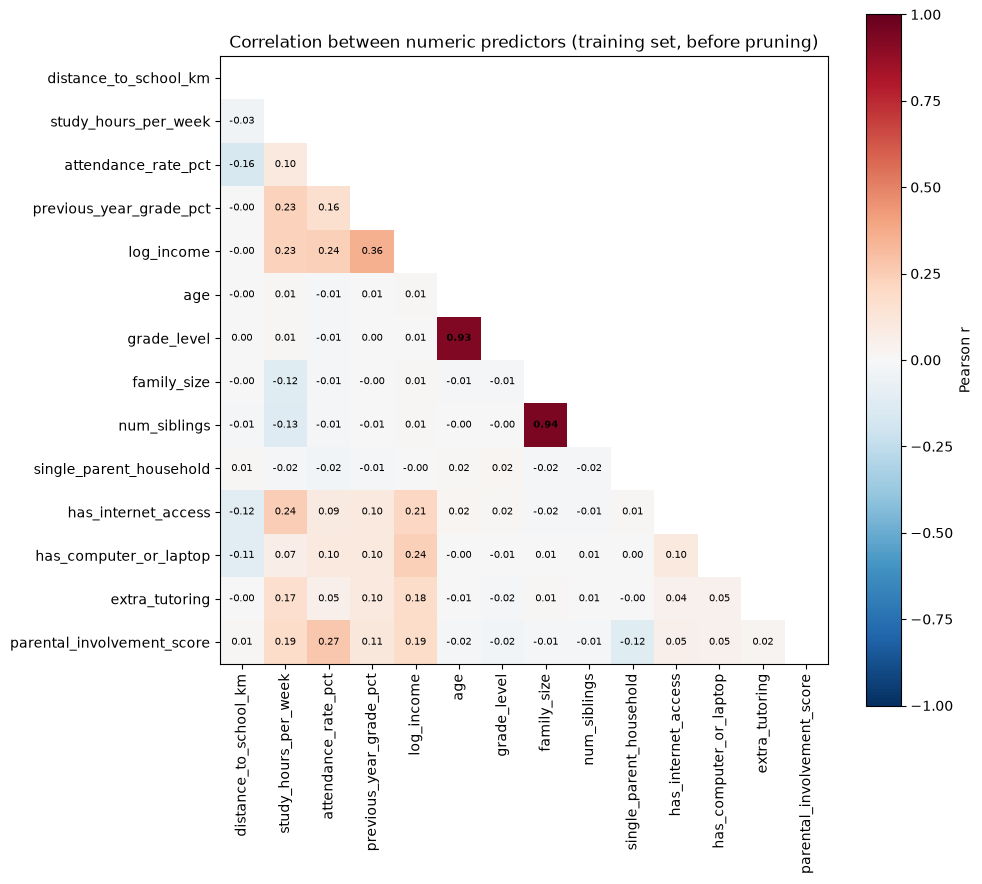

In [21]:
import matplotlib.pyplot as plt

CORR_THRESHOLD = 0.8

num_corr_all = X_train[NUMERIC_COLS].corr()
lower = num_corr_all.mask(np.triu(np.ones_like(num_corr_all, dtype=bool)))

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(lower.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC_COLS)), NUMERIC_COLS, rotation=90)
ax.set_yticks(range(len(NUMERIC_COLS)), NUMERIC_COLS)
for row in range(len(NUMERIC_COLS)):
    for col in range(row):
        r = num_corr_all.iloc[row, col]
        ax.text(col, row, f'{r:.2f}', ha='center', va='center', fontsize=7,
                fontweight='bold' if abs(r) > CORR_THRESHOLD else 'normal')
fig.colorbar(im, ax=ax, label='Pearson r')
ax.set_title('Correlation between numeric predictors (training set, before pruning)')
plt.tight_layout()
plt.show()

In [22]:
def source_variable(col):
    # Maps a one-hot column back to its raw predictor name
    for raw in PREDICTOR_COLS:
        if col == raw or col.startswith(raw + '_'):
            return raw
    return col


num_corr = X_train[NUMERIC_COLS].corr()
assoc_with_target = X_train[NUMERIC_COLS].corrwith(Y_train).abs()
high_pairs = [(a, b) for i, a in enumerate(NUMERIC_COLS) for b in NUMERIC_COLS[:i]
              if abs(num_corr.loc[a, b]) > CORR_THRESHOLD]

CORR_DROP = set()
for a, b in high_pairs:
    if a not in CORR_DROP and b not in CORR_DROP:
        CORR_DROP.add(a if assoc_with_target[a] < assoc_with_target[b] else b)

print('pairs above threshold:', high_pairs)
print('dropped for correlation:', sorted(CORR_DROP))

PRUNED_PREDICTORS = [p for p in PREDICTOR_COLS if p not in CORR_DROP]
PRUNED_COLS = [c for c in X_train.columns if source_variable(c) in PRUNED_PREDICTORS]
X_train = X_train[PRUNED_COLS]
X_test = X_test[PRUNED_COLS]
print(f'pruned: {len(PRUNED_PREDICTORS)} predictors ({len(PRUNED_COLS)} encoded columns)')

pairs above threshold: [('grade_level', 'age'), ('num_siblings', 'family_size')]
dropped for correlation: ['grade_level', 'num_siblings']
pruned: 22 predictors (52 encoded columns)


## Predictor selection (Lasso)

A single Lasso fit on the pruned training set shows which predictors it switches off. Numeric predictors are standardised inside the pipeline. The penalty is the largest one within one standard error of the best 10-fold CV score on the training rows. A predictor is kept if any of its encoded columns has a non-zero coefficient. The bar chart below shows every encoded coefficient; grey bars are the ones Lasso switched off. The test set is not used here.

CV-selected alpha: 0.0131  CV RMSE: 9.616
alpha at 1-SE: 0.1366
                            max |coef|        status
previous_year_grade_pct         4.8854          kept
log_income                      1.5396          kept
scholarship_status              1.1605          kept
study_hours_per_week            0.7482          kept
has_internet_access             0.6994          kept
has_computer_or_laptop          0.6499          kept
attendance_rate_pct             0.4243          kept
extra_tutoring                  0.3676          kept
mother_education_level          0.3653          kept
family_size                     0.2680          kept
single_parent_household         0.2012          kept
parental_involvement_score      0.0000  switched off
school_type                     0.0000  switched off
residence_type                  0.0000  switched off
distance_to_school_km           0.0000  switched off
family_income_bracket           0.0000  switched off
mother_occupation               0.0

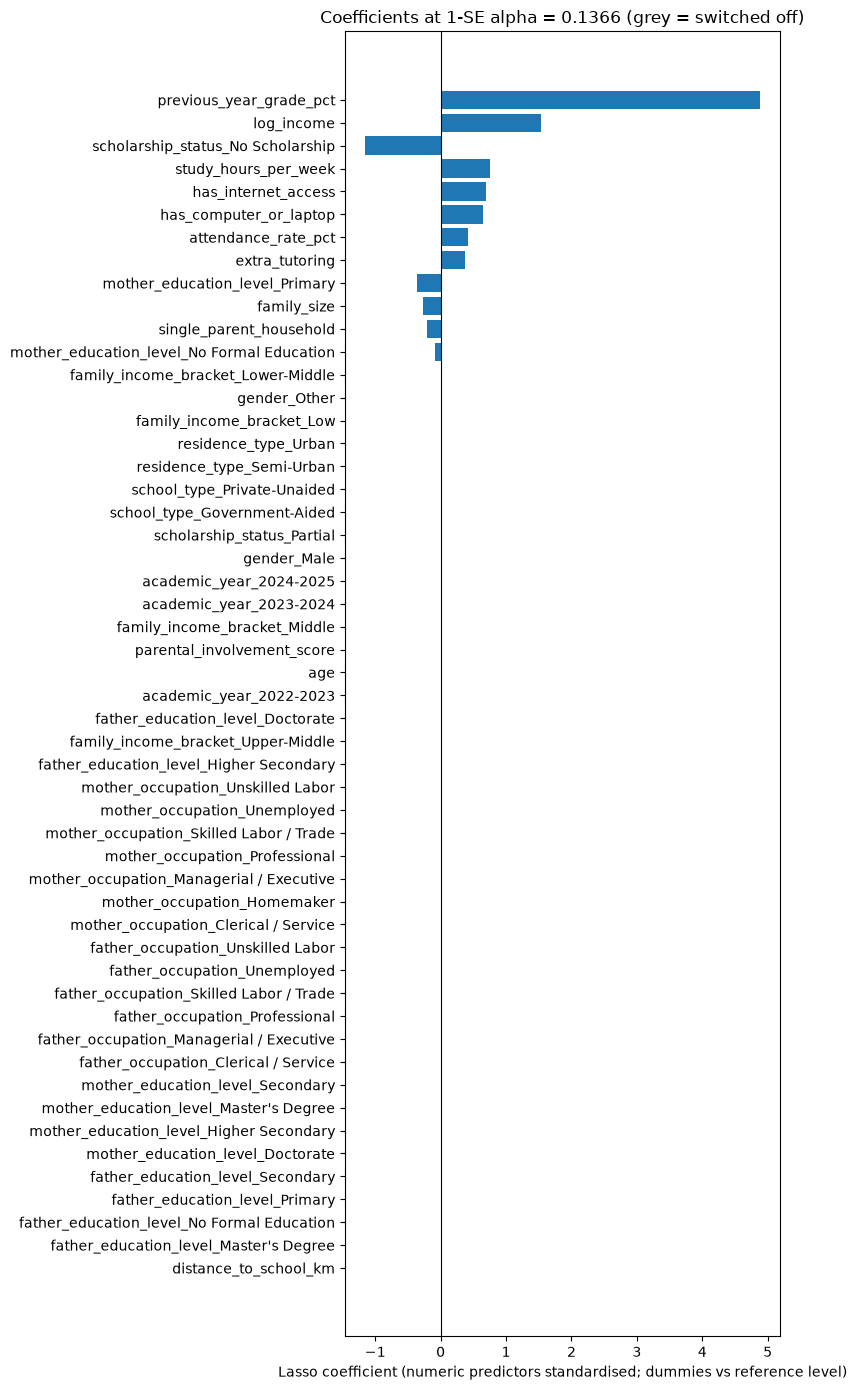

In [23]:
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

N_SPLITS = 10
ALPHA_GRID = np.logspace(-4, 1, 60)
ALL_COLS = list(X_train.columns)


def make_pipe(cols):
    # Continuous and discrete columns (including 0/1 flags) are scaled. One-hot dummy columns pass through unchanged.
    scale_cols = [c for c in cols if source_variable(c) in NUMERIC_COLS]
    scaling = ColumnTransformer([('scale', StandardScaler(), scale_cols)],
                                remainder='passthrough', verbose_feature_names_out=False)
    return make_pipeline(scaling.set_output(transform='pandas'), Lasso(max_iter=20000))


def one_se_alpha(search):
    # Largest alpha whose CV error is within one standard error of the best
    mean_rmse = -search.cv_results_['mean_test_score']
    se = search.cv_results_['std_test_score'] / np.sqrt(N_SPLITS)
    best = np.argmin(mean_rmse)
    return ALPHA_GRID[mean_rmse <= mean_rmse[best] + se[best]].max()


folds = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_train))
search = GridSearchCV(make_pipe(ALL_COLS), {'lasso__alpha': ALPHA_GRID}, cv=folds,
                      scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, Y_train)
ALPHA_1SE = one_se_alpha(search)
print(f'CV-selected alpha: {search.best_params_["lasso__alpha"]:.4f}  CV RMSE: {-search.best_score_:.3f}')
print(f'alpha at 1-SE: {ALPHA_1SE:.4f}')

lasso_fit = make_pipe(ALL_COLS).set_params(lasso__alpha=ALPHA_1SE).fit(X_train, Y_train)
lasso_coef = pd.Series(lasso_fit[-1].coef_, index=lasso_fit[:-1].get_feature_names_out())
predictor_of = lasso_coef.index.map(source_variable)

kept_levels = lasso_coef[lasso_coef != 0].index.map(source_variable)
SELECTED_PREDICTORS = [p for p in PRUNED_PREDICTORS if p in set(kept_levels)]
FINAL_COLS = [c for c in ALL_COLS if source_variable(c) in SELECTED_PREDICTORS]

summary = lasso_coef.abs().groupby(predictor_of).max().rename('max |coef|').to_frame()
summary['status'] = np.where(summary.index.isin(SELECTED_PREDICTORS), 'kept', 'switched off')
print(summary.sort_values('max |coef|', ascending=False).round(4).to_string())
print(f'kept {len(SELECTED_PREDICTORS)} of {len(PRUNED_PREDICTORS)} pruned predictors ({len(FINAL_COLS)} encoded columns)')

X_train_final = X_train[FINAL_COLS]
X_test_final = X_test[FINAL_COLS]

order = lasso_coef.abs().sort_values().index
bar_colors = ['tab:blue' if lasso_coef[c] != 0 else 'lightgray' for c in order]

fig, ax = plt.subplots(figsize=(8, 14))
ax.barh(order, lasso_coef[order], color=bar_colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Lasso coefficient (numeric predictors standardised; dummies vs reference level)')
ax.set_title(f'Coefficients at 1-SE alpha = {ALPHA_1SE:.4f} (grey = switched off)')
plt.tight_layout()
plt.show()

## Model comparison: shared setup

Every model is evaluated on the same 10 outer folds of the training set, using the predictors kept by the Lasso selection step. The helper below fits each model on the outer training folds, records the validation RMSE, then refits on all training rows and scores once on the test set. The mean-only baseline is run here as a reference.

In [24]:
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

MODEL_COLS = list(X_train_final.columns)
RIDGE_GRID = np.logspace(-3, 3, 50)
inner_cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
outer_folds = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_train_final))


def run_group(factories):
    # factories maps a model name to a function that returns a fresh, unfitted model
    cv_fold_rmse = {name: [] for name in factories}
    for fold, (train_idx, valid_idx) in enumerate(outer_folds, start=1):
        X_tr, X_valid = X_train_final.iloc[train_idx], X_train_final.iloc[valid_idx]
        Y_tr, Y_valid = Y_train.iloc[train_idx], Y_train.iloc[valid_idx]
        for name, make in factories.items():
            model = make().fit(X_tr, Y_tr)
            cv_fold_rmse[name].append(root_mean_squared_error(Y_valid, model.predict(X_valid)))
        print(f'Finished outer fold {fold}/{len(outer_folds)}')

    fitted, rows = {}, []
    for name, make in factories.items():
        model = make().fit(X_train_final, Y_train)
        if isinstance(model, GridSearchCV):
            print(f'{name} selected on all training rows: {model.best_params_}')
            fitted[name] = model.best_estimator_
        else:
            fitted[name] = model
        rows.append({
            'model': name,
            'cv_rmse': np.mean(cv_fold_rmse[name]),
            'cv_rmse_sd': np.std(cv_fold_rmse[name], ddof=1),
            'test_rmse': root_mean_squared_error(Y_test, model.predict(X_test_final)),
        })
    table = pd.DataFrame(rows).set_index('model')
    print(table.round(3).to_string())
    return {'cv_fold_rmse': cv_fold_rmse, 'fitted': fitted, 'table': table}


def scaled_model(cols, estimator):
    scale_cols = [c for c in cols if source_variable(c) in NUMERIC_COLS]
    scaling = ColumnTransformer([('scale', StandardScaler(), scale_cols)],
                                remainder='passthrough', verbose_feature_names_out=False)
    return make_pipeline(scaling.set_output(transform='pandas'), estimator)


baseline_results = run_group({'Mean only (baseline)': lambda: DummyRegressor(strategy='mean')})

Finished outer fold 1/10
Finished outer fold 2/10
Finished outer fold 3/10
Finished outer fold 4/10
Finished outer fold 5/10
Finished outer fold 6/10
Finished outer fold 7/10
Finished outer fold 8/10
Finished outer fold 9/10
Finished outer fold 10/10
                      cv_rmse  cv_rmse_sd  test_rmse
model                                               
Mean only (baseline)   11.695       0.134     11.708


### Linear models (OLS, Ridge, Lasso)

Ridge and Lasso are standardized inside each fold, and their penalties are chosen by the inner 10-fold CV. OLS uses the same scaling so the three share one pipeline shape.

Finished outer fold 1/10
Finished outer fold 2/10
Finished outer fold 3/10
Finished outer fold 4/10
Finished outer fold 5/10
Finished outer fold 6/10
Finished outer fold 7/10
Finished outer fold 8/10
Finished outer fold 9/10
Finished outer fold 10/10
Ridge selected on all training rows: {'ridge__alpha': np.float64(10.985411419875572)}
Lasso selected on all training rows: {'lasso__alpha': np.float64(0.0001)}
       cv_rmse  cv_rmse_sd  test_rmse
model                                
OLS      9.629       0.313      9.834
Ridge    9.629       0.312      9.835
Lasso    9.629       0.313      9.834


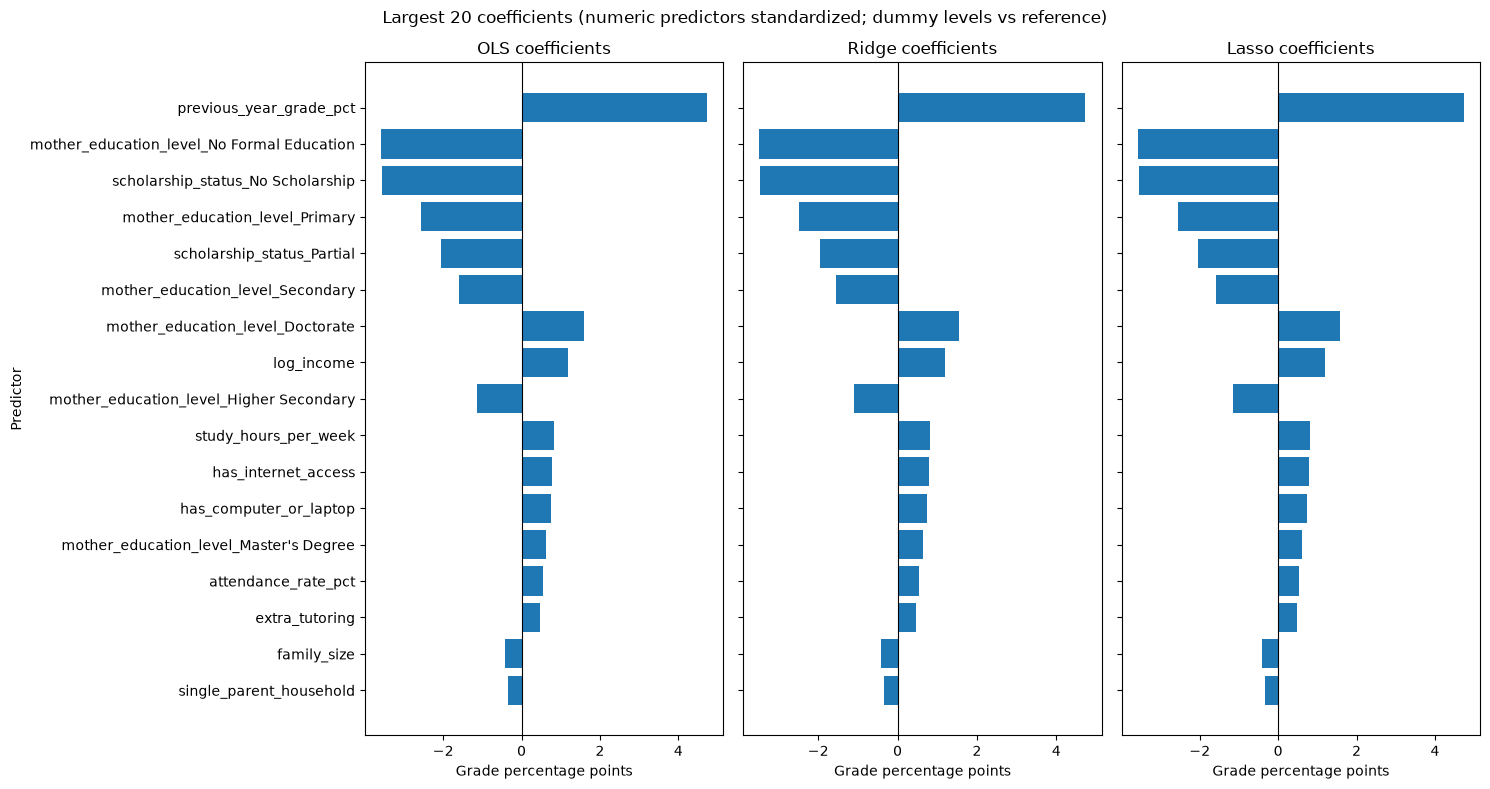

In [25]:
def tune_ridge():
    return GridSearchCV(scaled_model(MODEL_COLS, Ridge()), {'ridge__alpha': RIDGE_GRID},
                        cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)


def tune_lasso():
    return GridSearchCV(scaled_model(MODEL_COLS, Lasso(max_iter=20000)), {'lasso__alpha': ALPHA_GRID},
                        cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)


linear_results = run_group({
    'OLS': lambda: scaled_model(MODEL_COLS, LinearRegression()),
    'Ridge': tune_ridge,
    'Lasso': tune_lasso,
})

coef_series = {}
for name in ['OLS', 'Ridge', 'Lasso']:
    fitted = linear_results['fitted'][name]
    coef_series[name] = pd.Series(fitted[-1].coef_, index=fitted[:-1].get_feature_names_out())

largest = pd.concat(coef_series, axis=1).abs().max(axis=1)
feature_order = largest.nlargest(min(20, len(largest))).sort_values().index
fig, axes = plt.subplots(1, 3, figsize=(15, 8), sharey=True)
for ax, name in zip(axes, ['OLS', 'Ridge', 'Lasso']):
    ax.barh(feature_order, coef_series[name].loc[feature_order])
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{name} coefficients')
    ax.set_xlabel('Grade percentage points')
axes[0].set_ylabel('Predictor')
fig.suptitle('Largest 20 coefficients (numeric predictors standardized; dummy levels vs reference)')
plt.tight_layout()
plt.show()

### Tree models (Decision Tree, Random Forest)

Trees are invariant to scaling, so they use the raw predictors. Each model tunes its complexity with the same inner 10-fold CV.

In [26]:
def tune_tree():
    return GridSearchCV(DecisionTreeRegressor(random_state=SEED),
                        {'max_depth': [3, 4, 5, 6, 8, 10], 'min_samples_leaf': [10, 20, 50]},
                        cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)


def tune_forest():
    return GridSearchCV(RandomForestRegressor(n_estimators=200, random_state=SEED),
                        {'max_features': [0.33, 0.6, 1.0], 'min_samples_leaf': [5, 20]},
                        cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)


tree_results = run_group({
    'Decision Tree': tune_tree,
    'Random Forest': tune_forest,
})

importance = pd.Series(tree_results['fitted']['Random Forest'].feature_importances_, index=MODEL_COLS).sort_values()
importance.plot(kind='barh', figsize=(8, 5))
plt.title('Random Forest feature importance (impurity-based, all training rows)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

Finished outer fold 1/10
Finished outer fold 2/10
Finished outer fold 3/10
Finished outer fold 4/10
Finished outer fold 5/10


KeyboardInterrupt: 

### Combined comparison

All six models side by side, with paired tests on outer-fold errors. These tests are exploratory because folds share training observations.

                      cv_rmse  cv_rmse_sd  test_rmse
model                                               
Mean only (baseline)   11.623       0.372     11.834
OLS                     9.669       0.455      9.508
Ridge                   9.669       0.455      9.508
Lasso                   9.669       0.455      9.508
Decision Tree          10.004       0.472      9.931
Random Forest           9.775       0.465      9.663


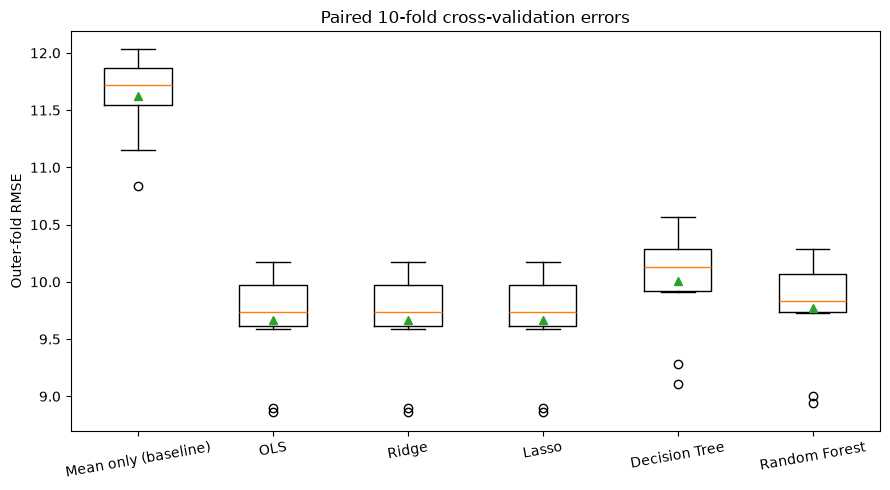

Paired t-test, Mean only (baseline) vs OLS (exploratory): p = 1.956e-10
Paired t-test, OLS vs Ridge (exploratory): p = 0.529
Paired t-test, OLS vs Lasso (exploratory): p = 0.3688
Paired t-test, OLS vs Decision Tree (exploratory): p = 7.46e-07
Paired t-test, OLS vs Random Forest (exploratory): p = 8.646e-07


In [ ]:
table_all = pd.concat([baseline_results['table'], linear_results['table'], tree_results['table']])
cv_fold_rmse = {**baseline_results['cv_fold_rmse'], **linear_results['cv_fold_rmse'], **tree_results['cv_fold_rmse']}
print(table_all.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([cv_fold_rmse[name] for name in table_all.index], showmeans=True)
ax.set_xticks(range(1, len(table_all) + 1), table_all.index, rotation=10)
ax.set_ylabel('Outer-fold RMSE')
ax.set_title('Paired 10-fold cross-validation errors')
plt.tight_layout()
plt.show()

for left, right in [
    ('Mean only (baseline)', 'OLS'),
    ('OLS', 'Ridge'),
    ('OLS', 'Lasso'),
    ('OLS', 'Decision Tree'),
    ('OLS', 'Random Forest'),
]:
    p_value = ttest_rel(cv_fold_rmse[left], cv_fold_rmse[right]).pvalue
    print(f'Paired t-test, {left} vs {right} (exploratory): p = {p_value:.4g}')

## Conclusion

The linear models are the strongest on this pipeline. Every model clearly beats the mean-only baseline, the linear models are statistically tied, and the tree-based models are worse than OLS.

- **Predictors help.** The mean-only baseline has CV RMSE 11.70. OLS, Ridge and Lasso reach 9.63, a reduction of about 18%, with paired p ≈ 6e-10.
- **Linear models are tied.** OLS, Ridge and Lasso all have CV RMSE 9.63 and fold SD about 0.31. OLS vs Ridge has p = 0.76 and OLS vs Lasso p = 0.46. Ridge's selected penalty (alpha about 11) barely changes the coefficients. The CV-selected Lasso penalty sits at the smallest value on the grid (0.0001), so Lasso is effectively OLS here.
- **Trees are worse.** Random Forest has CV RMSE 9.78 (max_features 0.33, min_samples_leaf 20), and the Decision Tree has 9.99 (max_depth 6, min_samples_leaf 50). Both are significantly worse than OLS (p ≈ 2e-5 and 6e-7).
- **Test set agrees.** Refitted on all training rows and scored once on the 1,800-row test set: mean only 11.71, OLS/Ridge/Lasso 9.83, Random Forest 9.94, Decision Tree 10.23.
- **Lasso switches off 11 of 22 pruned predictors.** The kept predictors are previous-year grade, log income, scholarship status, study hours, internet access, computer access, attendance, extra tutoring, mother's education, family size, and single-parent household. The switched-off ones are parental involvement, school type, residence type, distance to school, family income bracket, mother's occupation, age, gender, father's occupation, father's education, and academic year. Their coefficients are exactly zero in the coefficient chart.

**Interpretation.** Most of the signal is close to linear and additive. Previous-year grade, log income, and scholarship status have the largest coefficients, and study hours, internet and computer access, and attendance follow. The trees split the data into coarse regions and lose accuracy at this sample size.

**Caveats.** The target was kept on its original scale because log(Y) makes its skew worse (−0.51 to −2.55). No outlier capping was applied. Imputation statistics, correlation pruning, and the Lasso fit were computed once on the full training set before the outer CV, so the CV scores are somewhat optimistic. No separate nested check is run. The paired tests treat folds as independent, but they share training rows, so the p-values are exploratory. Results depend on the random seed.